# Stanford Cars Mini · Student Baseline · Frozen DINOv1

**Goal:** Train a classification head on pretrained, **frozen** DINOv1 features and produce `submission.csv` for the Kaggle competition.


## 0. Install libraries (run once)

In [3]:
%pip -q install timm scikit-learn pandas pillow tqdm matplotlib

## 1. Settings and folder checks

In [4]:

import kagglehub
import os

from google.colab import userdata

os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

# Download latest version
path = kagglehub.competition_download('idnn-swe-3052-assignment-3-flowers-classification')

print("Path to competition files:", path)

100%|██████████| 188M/188M [00:01<00:00, 115MB/s]

Extracting files...


Path to competition files: /root/.cache/kagglehub/competitions/idnn-swe-3052-assignment-3-flowers-classification


In [26]:
from pathlib import Path
import random, hashlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt

SEED_AUG = 123
SEED_HEAD = 42
random.seed(SEED_AUG)
np.random.seed(SEED_AUG)
torch.manual_seed(SEED_AUG)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_AUG)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# CHANGE THIS to the folder containing train/, val/, and test/.
DATA_ROOT = Path(path)
OUTPUT_DIR = Path('./student_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BATCH_SIZE = 32 if DEVICE == 'cuda' else 16
EPOCHS = 35
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-3
PATIENCE = 7

for name in ('train', 'val', 'test'):
    assert (DATA_ROOT / name).is_dir(), f'Missing {name}/ under {DATA_ROOT.resolve()}'
print('Data:', DATA_ROOT.resolve())
print('Device:', DEVICE)

Data: /root/.cache/kagglehub/competitions/idnn-swe-3052-assignment-3-flowers-classification
Device: cuda


## 2. Load labeled class folders with `ImageFolder`

In [6]:
# preprocessing change
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        224,
        scale=(0.8, 1.0),
        ratio=(0.9, 1.1),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

val_transform = transforms.Compose([
    transforms.Resize(
        256,
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])


train_ds = datasets.ImageFolder(DATA_ROOT / 'train', transform=train_transform)
val_ds = datasets.ImageFolder(DATA_ROOT / 'val', transform=val_transform)
preprocess = val_transform

assert train_ds.class_to_idx == val_ds.class_to_idx, 'train/ and val/ class folders must match'
NUM_CLASSES = len(train_ds.classes)
print('Classes:', NUM_CLASSES, '| Train:', len(train_ds), '| Val:', len(val_ds))
print('First class folders:', train_ds.classes[:5])
assert NUM_CLASSES == 20, f'Expected 20 classes, got {NUM_CLASSES}'

# Class-folder names from the instructor's export are prefixed by 000_, 001_, ...
# These prefixes make ImageFolder indices equal the Kaggle integer labels.
for i, folder in enumerate(train_ds.classes):
    assert folder.startswith(f'{i:03d}_'), f'Class-label mismatch at {folder}; ask your instructor'


Classes: 20 | Train: 700 | Val: 200
First class folders: ['000_Audi_R8_Coupe_2012', '001_Audi_S4_Sedan_2007', '002_Audi_S5_Convertible_2012', '003_Audi_V8_Sedan_1994', '004_BMW_X6_SUV_2012']


## 3. Discover unlabeled test images and IDs

The `image_id` column must match `sample_submission.csv` exactly. The test folder stays flat, without class-name folders.

In [7]:
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
test_dir = DATA_ROOT / 'test'
test_files = sorted(p for p in test_dir.iterdir() if p.is_file() and p.suffix.lower() in EXTENSIONS)
assert test_files, f'No images found inside {test_dir.resolve()}'

sample_path = DATA_ROOT / 'sample_submission.csv'
if sample_path.exists():
    sample = pd.read_csv(sample_path, dtype={'image_id': str})
    assert {'image_id','label'}.issubset(sample.columns)
    required_ids = sample['image_id'].astype(str).tolist()
else:
    required_ids = sorted(p.stem for p in test_files)

by_id = {p.stem: p for p in test_files}
assert len(by_id) == len(test_files), 'Two test filenames share the same image_id stem'
assert len(set(required_ids)) == len(required_ids), 'Duplicate image_id in sample_submission.csv'
assert set(required_ids) == set(by_id), ('Test image IDs do not match sample_submission.csv',
                                         len(set(required_ids)-set(by_id)), len(set(by_id)-set(required_ids)))
print('Unlabeled test images:', len(required_ids))
print('Submission ID example:', required_ids[:3])

class TestImages(Dataset):
    def __init__(self, ids): self.ids = ids
    def __len__(self): return len(self.ids)
    def __getitem__(self, index):
        p = by_id[self.ids[index]]
        with Image.open(p) as im: image = preprocess(im.convert('RGB'))
        return image

test_ds = TestImages(required_ids)

Unlabeled test images: 700
Submission ID example: ['car_000000', 'car_000008', 'car_000010']


## 4. Load frozen DINOv1 ViT-S/16

The pretrained model weights may download on the first run. Dataset images are read exclusively from local folders.

In [8]:

# Experiment F0 — DINOv2 ViT-S/14

MODEL_NAME = "dinov2_vits14"

backbone = torch.hub.load(
    "facebookresearch/dinov2",
    MODEL_NAME
).to(DEVICE)

# Frozen feature extractor
backbone.eval()

for param in backbone.parameters():
    param.requires_grad_(False)

FEATURE_DIM = backbone.embed_dim

assert FEATURE_DIM == 384

# Verify output shape
with torch.inference_mode():
    dummy = torch.randn(2, 3, 224, 224, device=DEVICE)
    features = backbone(dummy)

assert features.shape == (2, 384), features.shape

print("Backbone:", MODEL_NAME)
print("Feature dimension:", FEATURE_DIM)
print("Test output shape:", features.shape)

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 218MB/s]


Backbone: dinov2_vits14
Feature dimension: 384
Test output shape: torch.Size([2, 384])


## 5. Extract and cache 384-D DINO features

The backbone stays frozen; only the classification head will learn. Cache is checked against file names, sizes, modification times, and class mapping. Delete the cached file when changing the model or preprocessing.

In [9]:

# Experiment configuration
EXPERIMENT = "P3_geometry_multiview"
N_AUG = 4
INCLUDE_ORIGINAL = True
SEED = 123

# Reproducibility
random.seed(SEED_AUG)
np.random.seed(SEED_AUG)
torch.manual_seed(SEED_AUG)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_AUG)

# Cache signature
def dataset_signature():
    paths = (
        [Path(p) for p, _ in train_ds.samples + val_ds.samples]
        + [by_id[i] for i in required_ids]
    )

    parts = [
        MODEL_NAME,
        EXPERIMENT,
        repr(train_transform),
        repr(val_transform),
        str(N_AUG),
        str(INCLUDE_ORIGINAL),
        str(SEED),
        str(train_ds.class_to_idx)
    ]

    for p in paths:
        st = p.stat()
        parts.append(
            f'{p.resolve()}|{st.st_size}|{st.st_mtime_ns}'
        )

    return hashlib.sha256(
        '\n'.join(parts).encode()
    ).hexdigest()


CACHE = OUTPUT_DIR / (
    f"{MODEL_NAME}_{EXPERIMENT}_"
    f"augseed{SEED_AUG}_features.pt"
)
signature = dataset_signature()


@torch.inference_mode()
def extract(loader, desc):
    embeddings = []
    backbone.eval()

    for batch in tqdm(loader, desc=desc):
        x = batch[0] if isinstance(batch, (tuple, list)) else batch
        z = backbone(x.to(DEVICE)).float()

        assert z.ndim == 2 and z.shape[1] == FEATURE_DIM
        embeddings.append(z.cpu())

    return torch.cat(embeddings)


kwargs = dict(
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE == 'cuda')
)

# Check cache
if CACHE.exists():
    try:
        cached = torch.load(
            CACHE, map_location='cpu', weights_only=True
        )
    except TypeError:
        cached = torch.load(CACHE, map_location='cpu')
else:
    cached = None


if cached is not None and cached.get('signature') == signature:
    print("Reusing feature cache:", CACHE)

    X_train = cached['X_train']
    X_val = cached['X_val']
    X_test = cached['X_test']

else:
    train_views = []
    original_transform = train_ds.transform

    try:
        if INCLUDE_ORIGINAL:
            train_ds.transform = val_transform
            train_views.append(
                extract(
                    DataLoader(train_ds, **kwargs),
                    'Original training features'
                )
            )

        train_ds.transform = train_transform

        for i in range(N_AUG):
            train_views.append(
                extract(
                    DataLoader(train_ds, **kwargs),
                    f'Augmented view {i+1}/{N_AUG}'
                )
            )
    finally:
        train_ds.transform = original_transform

    X_train = torch.cat(train_views, dim=0)

    X_val = extract(
        DataLoader(val_ds, **kwargs),
        'Validation features'
    )

    X_test = extract(
        DataLoader(test_ds, **kwargs),
        'Test features'
    )

    torch.save({
        'signature': signature,
        'X_train': X_train,
        'X_val': X_val,
        'X_test': X_test
    }, CACHE)


# Labels
NUM_VIEWS = N_AUG + int(INCLUDE_ORIGINAL)

y_train = torch.tensor(
    train_ds.targets, dtype=torch.long
).repeat(NUM_VIEWS)

y_val = torch.tensor(
    val_ds.targets, dtype=torch.long
)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(required_ids)

FEATURES_SIGNATURE = signature
FEATURES_MODEL_NAME = MODEL_NAME

print("Model:", MODEL_NAME)
print("Preprocessing:", EXPERIMENT)
print("Feature cache:", CACHE)
print("X_train:", X_train.shape)
print('y_train:', y_train.shape)
print('X_val:', X_val.shape)
print('X_test:', X_test.shape)

Original training features:   0%|          | 0/22 [00:00<?, ?it/s]

Augmented view 1/4:   0%|          | 0/22 [00:00<?, ?it/s]

Augmented view 2/4:   0%|          | 0/22 [00:00<?, ?it/s]

Augmented view 3/4:   0%|          | 0/22 [00:00<?, ?it/s]

Augmented view 4/4:   0%|          | 0/22 [00:00<?, ?it/s]

Validation features:   0%|          | 0/7 [00:00<?, ?it/s]

Test features:   0%|          | 0/22 [00:00<?, ?it/s]

Model: dinov2_vits14
Preprocessing: P3_geometry_multiview
Feature cache: student_outputs/dinov2_vits14_P3_geometry_multiview_augseed123_features.pt
X_train: torch.Size([3500, 384])
y_train: torch.Size([3500])
X_val: torch.Size([200, 384])
X_test: torch.Size([700, 384])


## 6. Standardize features using **training data only**

In [10]:
feature_mean = X_train.mean(dim=0)
feature_std = X_train.std(dim=0, unbiased=False).clamp_min(1e-6)
Z_train = (X_train - feature_mean) / feature_std
Z_val = (X_val - feature_mean) / feature_std
Z_test = (X_test - feature_mean) / feature_std
print('Features standardized without validation/test leakage.')

Features standardized without validation/test leakage.


## 7. Train the provided **linear** classification head

This is the baseline students should improve. Feel free to test an MLP, regularization, different DINO token pooling, or other allowed techniques while keeping the backbone frozen.

In [27]:
HEAD_CONFIGS = {
    "E0_linear": {
        "hidden_dim": None,
        "use_bn": False,
        "dropout": 0.0
    },
    "E1_mlp": {
        "hidden_dim": 128,
        "use_bn": False,
        "dropout": 0.0
    },
    "E2_mlp_bn": {
        "hidden_dim": 128,
        "use_bn": True,
        "dropout": 0.0
    },
    "E3_mlp_bn_drop01": {
        "hidden_dim": 128,
        "use_bn": True,
        "dropout": 0.1
    },
    "E4_mlp_bn_drop03": {
        "hidden_dim": 128,
        "use_bn": True,
        "dropout": 0.3
    }
}


def build_head(experiment, input_dim, num_classes):
    cfg = HEAD_CONFIGS[experiment]

    if cfg["hidden_dim"] is None:
        return nn.Linear(input_dim, num_classes)

    layers = [
        nn.Linear(input_dim, cfg["hidden_dim"])
    ]

    if cfg["use_bn"]:
        layers.append(
            nn.BatchNorm1d(cfg["hidden_dim"])
        )

    layers.append(nn.ReLU())

    if cfg["dropout"] > 0:
        layers.append(nn.Dropout(cfg["dropout"]))

    layers.append(
        nn.Linear(cfg["hidden_dim"], num_classes)
    )

    return nn.Sequential(*layers)

In [34]:

# H1 — Check available classifier checkpoints

H1_SEEDS = [123, 42, 2026]

checkpoint_paths = {
    seed: OUTPUT_DIR / (
        f"dinov2_p3_e4_aug123_head{seed}.pt"
    )
    for seed in H1_SEEDS
}

for seed, path in checkpoint_paths.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"Seed {seed}: {status} — {path}")

missing = [
    seed for seed, path in checkpoint_paths.items()
    if not path.exists()
]

assert not missing, (
    f"Missing checkpoints for seeds {missing}. "
    "Restore them or retrain only those classifier heads."
)

assert MODEL_NAME == "dinov2_vits14"
assert FEATURES_MODEL_NAME == MODEL_NAME
assert FEATURES_SIGNATURE == dataset_signature()

print("All checkpoints and feature cache verified.")

# H1 — Load classifiers and saved normalization statistics

ensemble_models = {}

for seed in H1_SEEDS:
    ckpt = torch.load(
        checkpoint_paths[seed],
        map_location="cpu",
        weights_only=True
    )

    assert ckpt["backbone"] == "dinov2_vits14"
    assert ckpt["preprocessing"] == "P3_geometry_multiview"
    assert ckpt["head_experiment"] == "E4_mlp_bn_drop03"
    assert ckpt["seed_aug"] == 123
    assert ckpt["seed_head"] == seed
    assert ckpt["class_to_idx"] == train_ds.class_to_idx

    model_head = build_head(
        ckpt["head_experiment"],
        FEATURE_DIM,
        NUM_CLASSES
    ).to(DEVICE)

    model_head.load_state_dict(
        ckpt["head_state_dict"]
    )
    model_head.eval()

    ensemble_models[seed] = {
        "head": model_head,
        "mean": ckpt["feature_mean"].to(DEVICE),
        "std": ckpt["feature_std"].to(DEVICE)
    }

    print(
        f"Loaded seed {seed} | "
        f"Saved accuracy: {ckpt['best_accuracy']:.2%}"
    )
@torch.inference_mode()
def predict_probabilities(seed, features):
    item = ensemble_models[seed]

    head = item["head"]
    feature_mean = item["mean"]
    feature_std = item["std"]

    # Standardize using this checkpoint's statistics
    z = features.to(DEVICE)
    z = (z - feature_mean) / feature_std

    logits = head(z)
    return torch.softmax(logits, dim=1).cpu()


val_probs = {
    seed: predict_probabilities(seed, X_val)
    for seed in H1_SEEDS
}

# Average class probabilities
val_pair = (
    val_probs[42] + val_probs[2026]
) / 2

val_three = (
    val_probs[123]
    + val_probs[42]
    + val_probs[2026]
) / 3

print("Individual predictions:", val_probs[2026].shape)
print("Two-head ensemble:", val_pair.shape)
print("Three-head ensemble:", val_three.shape)

# H1 — Compare individual heads and ensembles

y_true = np.array(val_ds.targets)

variants = {
    "Seed 123": val_probs[123],
    "Seed 42": val_probs[42],
    "Seed 2026": val_probs[2026],
    "Ensemble 42+2026": val_pair,
    "Ensemble 123+42+2026": val_three
}

results = []

for name, probabilities in variants.items():
    predictions = probabilities.argmax(dim=1).numpy()

    acc = accuracy_score(y_true, predictions)
    macro_f1 = f1_score(
        y_true,
        predictions,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Macro-F1": macro_f1,
        "Correct": int((predictions == y_true).sum())
    })

results_df = pd.DataFrame(results)

display(results_df)

best_row = results_df.sort_values(
    ["Accuracy", "Macro-F1"],
    ascending=False
).iloc[0]

print(
    "Best validation model:",
    best_row["Model"]
)


Seed 123: FOUND — student_outputs/dinov2_p3_e4_aug123_head123.pt
Seed 42: FOUND — student_outputs/dinov2_p3_e4_aug123_head42.pt
Seed 2026: FOUND — student_outputs/dinov2_p3_e4_aug123_head2026.pt
All checkpoints and feature cache verified.
Loaded seed 123 | Saved accuracy: 96.00%
Loaded seed 42 | Saved accuracy: 97.00%
Loaded seed 2026 | Saved accuracy: 98.00%
Individual predictions: torch.Size([200, 20])
Two-head ensemble: torch.Size([200, 20])
Three-head ensemble: torch.Size([200, 20])


,Model,Accuracy,Macro-F1,Correct
0,Seed 123,0.960,0.960215,192
1,Seed 42,0.970,0.970078,194
2,Seed 2026,0.980,0.980279,196
3,Ensemble 42+2026,0.975,0.974861,195
4,Ensemble 123+42+2026,0.970,0.969773,194


Best validation model: Seed 2026


In [28]:
from torch.utils.data import TensorDataset
training_loader = DataLoader(TensorDataset(Z_train, y_train), batch_size=64,
                             shuffle=True, num_workers=0)
HEAD_EXPERIMENT = "E4_mlp_bn_drop03"

# Ensure features match the selected backbone
assert FEATURES_MODEL_NAME == MODEL_NAME
assert FEATURES_SIGNATURE == dataset_signature(), (
    "Feature configuration changed. "
    "Rerun Sections 5 and 6."
)

# Reset classifier randomness
random.seed(SEED_HEAD)
np.random.seed(SEED_HEAD)
torch.manual_seed(SEED_HEAD)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_HEAD)

# Reproducible training data order
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED_HEAD)

training_loader = DataLoader(
    TensorDataset(Z_train, y_train),
    batch_size=64,
    shuffle=True,
    num_workers=0,
    generator=loader_generator
)

# Fresh classifier for each experiment
head = build_head(
    HEAD_EXPERIMENT,
    FEATURE_DIM,
    NUM_CLASSES
).to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    head.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)
print("Experiment:", HEAD_EXPERIMENT)
print("Head seed:", SEED_HEAD)
print("Architecture:")
print(head)

best_accuracy = -1.0
best_weights = None
bad_epochs = 0
history = []
for epoch in range(1, EPOCHS + 1):
    head.train()
    running_loss = 0.0
    for xb, yb in training_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(head(xb), yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(yb)
    head.eval()
    with torch.inference_mode():
        val_pred = head(Z_val.to(DEVICE)).argmax(dim=1).cpu().numpy()
    val_accuracy = accuracy_score(y_val.numpy(), val_pred)
    history.append({'epoch': epoch, 'train_loss': running_loss / len(Z_train),
                    'val_accuracy': val_accuracy})
    print(f'Epoch {epoch:02d}/{EPOCHS} | train loss: {history[-1]["train_loss"]:.4f} | val accuracy: {val_accuracy:.2%}')
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_weights = {key: value.detach().cpu().clone() for key, value in head.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print('Early stopping: validation accuracy did not improve')
            break

head.load_state_dict(best_weights)
head.eval()
print(f'Best validation accuracy: {best_accuracy:.2%}')
# pd.DataFrame(history).to_csv(OUTPUT_DIR / 'training_history.csv', index=False)

# torch.save({'head_state_dict': best_weights, 'feature_mean': feature_mean,
#             'feature_std': feature_std, 'class_to_idx': train_ds.class_to_idx,
#             'backbone': MODEL_NAME}, OUTPUT_DIR / 'linear_head.pt')

RUN_NAME = (
    f"dinov2_p3_e4_aug{SEED_AUG}_head{SEED_HEAD}"
)

checkpoint_path = OUTPUT_DIR / f"{RUN_NAME}.pt"
submission_path = OUTPUT_DIR / f"{RUN_NAME}.csv"

pd.DataFrame(history).to_csv(
    OUTPUT_DIR / f"{RUN_NAME}_history.csv",
    index=False
)

torch.save({
    "head_state_dict": best_weights,
    "feature_mean": feature_mean,
    "feature_std": feature_std,
    "class_to_idx": train_ds.class_to_idx,
    "backbone": MODEL_NAME,
    "preprocessing": EXPERIMENT,
    "head_experiment": HEAD_EXPERIMENT,
    "head_config": HEAD_CONFIGS[HEAD_EXPERIMENT],
    "seed_aug": SEED_AUG,
    "seed_head": SEED_HEAD,
    "best_accuracy": best_accuracy
}, OUTPUT_DIR / f"{RUN_NAME}.pt")

print("Saved experiment:", RUN_NAME)


Experiment: E4_mlp_bn_drop03
Head seed: 42
Architecture:
Sequential(
  (0): Linear(in_features=384, out_features=128, bias=True)
  (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=128, out_features=20, bias=True)
)
Epoch 01/35 | train loss: 1.6150 | val accuracy: 89.50%
Epoch 02/35 | train loss: 0.5491 | val accuracy: 93.50%
Epoch 03/35 | train loss: 0.2309 | val accuracy: 94.00%
Epoch 04/35 | train loss: 0.1192 | val accuracy: 95.00%
Epoch 05/35 | train loss: 0.0720 | val accuracy: 96.00%
Epoch 06/35 | train loss: 0.0463 | val accuracy: 96.00%
Epoch 07/35 | train loss: 0.0344 | val accuracy: 96.50%
Epoch 08/35 | train loss: 0.0273 | val accuracy: 97.00%
Epoch 09/35 | train loss: 0.0203 | val accuracy: 96.50%
Epoch 10/35 | train loss: 0.0171 | val accuracy: 96.50%
Epoch 11/35 | train loss: 0.0143 | val accuracy: 96.50%
Epoch 12/35 | train loss: 0.0125 | val accuracy: 96.00%

In [29]:

# H0: Load the best DINOv2 checkpoint
H0_NAME = "H0_dinov2_p3_e4_flip_tta"

CKPT_PATH = OUTPUT_DIR / "dinov2_p3_e4_aug123_head2026.pt"

assert CKPT_PATH.exists(), (
    f"Checkpoint not found: {CKPT_PATH}\n"
    "Restore your saved F0 seed-2026 checkpoint first."
)

ckpt = torch.load(
    CKPT_PATH,
    map_location="cpu",
    weights_only=True
)

assert ckpt["backbone"] == "dinov2_vits14"
assert MODEL_NAME == ckpt["backbone"]
assert ckpt["head_experiment"] == "E4_mlp_bn_drop03"
assert ckpt["seed_head"] == 2026
assert ckpt["class_to_idx"] == train_ds.class_to_idx

# Reconstruct the original classification head
head = build_head(
    ckpt["head_experiment"],
    FEATURE_DIM,
    NUM_CLASSES
).to(DEVICE)

head.load_state_dict(ckpt["head_state_dict"])

# Use the normalization statistics saved with this head
feature_mean = ckpt["feature_mean"].to(DEVICE)
feature_std = ckpt["feature_std"].to(DEVICE)

assert feature_mean.numel() == FEATURE_DIM
assert feature_std.numel() == FEATURE_DIM

head.eval()
backbone.eval()

print("Checkpoint:", CKPT_PATH)
print("Backbone:", ckpt["backbone"])
print("Head:", ckpt["head_experiment"])
print("Head seed:", ckpt["seed_head"])
print("Saved validation accuracy:", ckpt["best_accuracy"])


Checkpoint: student_outputs/dinov2_p3_e4_aug123_head2026.pt
Backbone: dinov2_vits14
Head: E4_mlp_bn_drop03
Head seed: 2026
Saved validation accuracy: 0.98


In [30]:

# H0: Original + horizontal-flip inference
from torch.utils.data import DataLoader

TTA_BATCH_SIZE = 16

h0_val_loader = DataLoader(
    val_ds,
    batch_size=TTA_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

h0_test_loader = DataLoader(
    test_ds,
    batch_size=TTA_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


@torch.inference_mode()
def predict_original_and_flip(loader):
    backbone.eval()
    head.eval()

    original_probs = []
    flipped_probs = []

    for batch in tqdm(loader, desc="TTA inference"):
        images = (
            batch[0]
            if isinstance(batch, (list, tuple))
            else batch
        )

        images = images.to(DEVICE)
        n = images.size(0)

        # Horizontal flip along image width
        flipped = torch.flip(images, dims=[-1])

        # Process original and flipped images together
        combined = torch.cat(
            [images, flipped],
            dim=0
        )

        features = backbone(combined).float()

        # Apply F0 training-set normalization
        features = (
            features - feature_mean
        ) / feature_std

        logits = head(features)
        probs = torch.softmax(logits, dim=1)

        original_probs.append(probs[:n].cpu())
        flipped_probs.append(probs[n:].cpu())

    return (
        torch.cat(original_probs, dim=0),
        torch.cat(flipped_probs, dim=0)
    )


## 8. Validate and inspect the baseline

Validation accuracy: 98.00%
Validation macro-F1: 0.9803


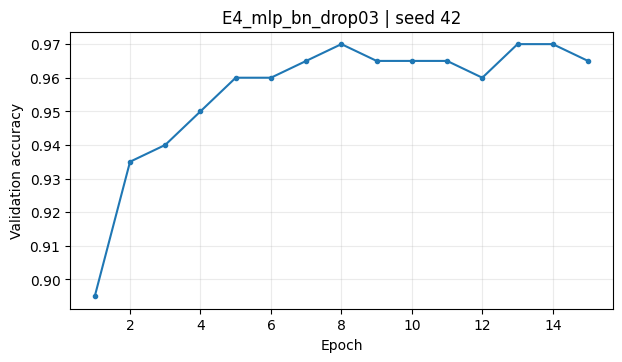

In [31]:
with torch.inference_mode():
    val_logits = head(Z_val.to(DEVICE))
    val_prediction = val_logits.argmax(dim=1).cpu().numpy()
print('Validation accuracy:', f'{accuracy_score(y_val.numpy(), val_prediction):.2%}')
print('Validation macro-F1:', f'{f1_score(y_val.numpy(), val_prediction, average="macro"):.4f}')

hist = pd.DataFrame(history)
plt.figure(figsize=(7, 3.6))
plt.plot(hist.epoch, hist.val_accuracy, marker='o', markersize=3)
plt.xlabel('Epoch'); plt.ylabel('Validation accuracy'); plt.title(f"{HEAD_EXPERIMENT} | seed {SEED_HEAD}")
plt.grid(alpha=.25); plt.show()

In [32]:

# Generate validation predictions
val_orig, val_flip = predict_original_and_flip(
    h0_val_loader
)

val_tta = (val_orig + val_flip) / 2

y_true = np.array(val_ds.targets)

pred_orig = val_orig.argmax(dim=1).numpy()
pred_flip = val_flip.argmax(dim=1).numpy()
pred_tta = val_tta.argmax(dim=1).numpy()


def print_metrics(name, predictions):
    acc = accuracy_score(y_true, predictions)
    f1 = f1_score(
        y_true,
        predictions,
        average="macro"
    )
    print(
        f"{name:16s} | "
        f"Accuracy: {acc:.2%} | "
        f"Macro-F1: {f1:.4f}"
    )
    return acc


acc_orig = print_metrics("Original", pred_orig)
acc_flip = print_metrics("Flip only", pred_flip)
acc_tta = print_metrics("Flip TTA", pred_tta)

print(
    "Changed predictions:",
    np.count_nonzero(pred_orig != pred_tta)
)

print(
    "Original correct:",
    np.sum(pred_orig == y_true)
)
print(
    "TTA correct:",
    np.sum(pred_tta == y_true)
)

if not np.isclose(acc_orig, 0.98):
    print(
        "WARNING: Original accuracy did not reproduce "
        "the F0 seed-2026 result. Verify checkpoint, "
        "backbone, and validation preprocessing."
    )


TTA inference:   0%|          | 0/13 [00:00<?, ?it/s]

Original         | Accuracy: 98.00% | Macro-F1: 0.9803
Flip only        | Accuracy: 96.00% | Macro-F1: 0.9591
Flip TTA         | Accuracy: 96.00% | Macro-F1: 0.9593
Changed predictions: 4
Original correct: 196
TTA correct: 192


## 9. Predict unlabeled test images and make Kaggle submission

There are no test labels in this notebook. Make sure your output has **exactly two columns**: `image_id,label`, matching the order of `sample_submission.csv`. Kaggle competition scoring should use integer class labels.

In [24]:
with torch.inference_mode():
    test_logits = head(Z_test.to(DEVICE))
    test_predictions = test_logits.argmax(dim=1).cpu().numpy().astype(int)

submission = pd.DataFrame({'image_id': required_ids, 'label': test_predictions})
assert submission['label'].between(0, NUM_CLASSES-1).all()
assert len(submission) == len(test_files)
assert submission.image_id.is_unique
if sample_path.exists():
    original = pd.read_csv(sample_path, dtype={'image_id': str})
    assert submission['image_id'].tolist() == original['image_id'].tolist()

submission_path = OUTPUT_DIR / f'{RUN_NAME}_submission.csv'
submission.to_csv(submission_path, index=False)
print('Saved Kaggle submission:', submission_path.resolve())
print('Number of predictions:', len(submission))
display(submission.head(10))

Saved Kaggle submission: /content/student_outputs/dinov2_p3_e4_aug123_head2026_submission.csv
Number of predictions: 700


,image_id,label
0,car_000000,6
1,car_000008,3
2,car_000010,6
3,car_000011,8
4,car_000012,18
5,car_000013,0
6,car_000019,7
7,car_000021,18
8,car_000023,3
9,car_000026,15


In [25]:

# Generate original and flipped test probabilities
test_orig, test_flip = predict_original_and_flip(
    h0_test_loader
)

test_tta = (test_orig + test_flip) / 2

original_predictions = (
    test_orig.argmax(dim=1).numpy().astype(int)
)

tta_predictions = (
    test_tta.argmax(dim=1).numpy().astype(int)
)

print(
    "Test predictions changed by TTA:",
    np.count_nonzero(
        original_predictions != tta_predictions
    )
)

submission = pd.DataFrame({
    "image_id": required_ids,
    "label": tta_predictions
})

assert len(submission) == len(required_ids)
assert submission["image_id"].is_unique
assert submission["label"].between(
    0, NUM_CLASSES - 1
).all()

if sample_path.exists():
    original_sample = pd.read_csv(
        sample_path,
        dtype={"image_id": str}
    )
    assert submission["image_id"].tolist() == (
        original_sample["image_id"].tolist()
    )

submission_path = OUTPUT_DIR / f"{H0_NAME}_submission.csv"

submission.to_csv(
    submission_path,
    index=False
)

print("Saved:", submission_path)
display(submission.head())


TTA inference:   0%|          | 0/44 [00:00<?, ?it/s]

Test predictions changed by TTA: 7
Saved: student_outputs/H0_dinov2_p3_e4_flip_tta_submission.csv


,image_id,label
0,car_000000,6
1,car_000008,3
2,car_000010,6
3,car_000011,8
4,car_000012,18
